<a href="https://colab.research.google.com/github/2303A51638/ARVR-Project/blob/main/ARVR_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running execution on computational device: cpu
>> Successfully loaded air quality dataset from: Data.xlsx
>> Initial dataset dimensions: 2183 rows, 6 columns
>> Imputing 12 missing values in Solar Radiation (SR) using chronological interpolation...
>> Missing values audit post-imputation:
PM2.5    0
RH       0
WD       0
SR       0
BP       0
AT       0
dtype: int64

DESCRIPTIVE SUMMARY STATISTICS OF MONITORING DATA
        Count    Mean  Std Dev    Min  Median    Max
PM2.5  2183.0  147.02    72.67    1.0   139.0  427.0
RH     2183.0   65.85    15.57   36.0    68.0   95.0
WD     2183.0  159.84    67.84    7.0   153.0  332.0
SR     2183.0  126.40   142.63    2.0     6.0  334.0
BP     2183.0  737.65     6.29  726.0   740.0  749.0
AT     2183.0   15.03     2.75   11.0    15.0   23.0

>> Created sequential temporal dataset: 2176 sequences of length 8

TRAINING HIGHWAY LSTM NEURAL NETWORK
Epoch [01/45] - Train Loss: 0.7063 | Validation Loss: 0.6578
Epoch [05/45] - Train Loss: 0.5614 | Valid

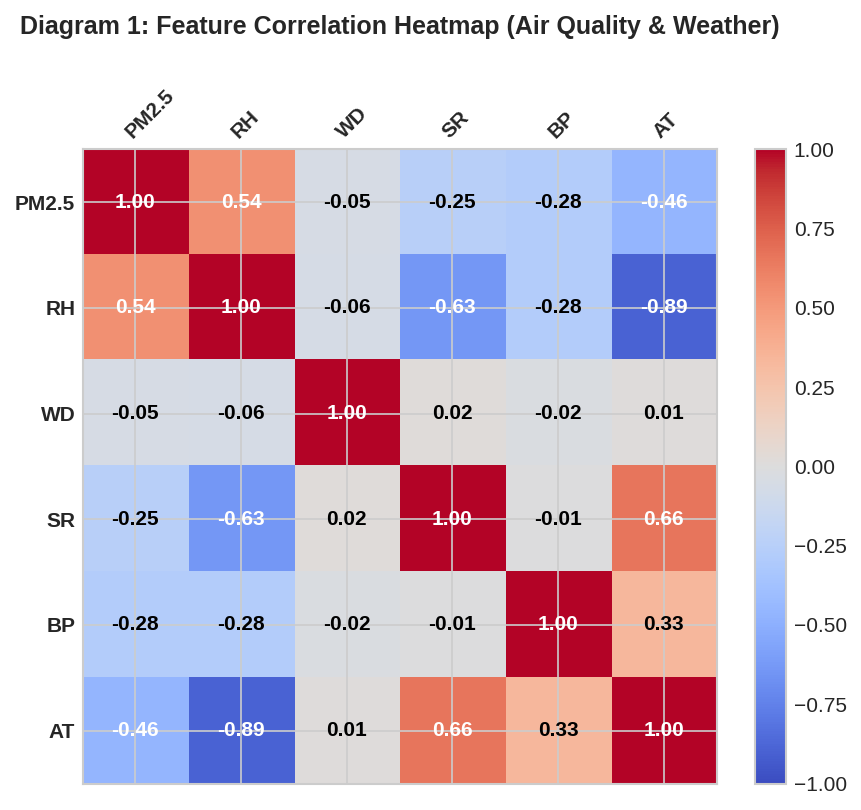

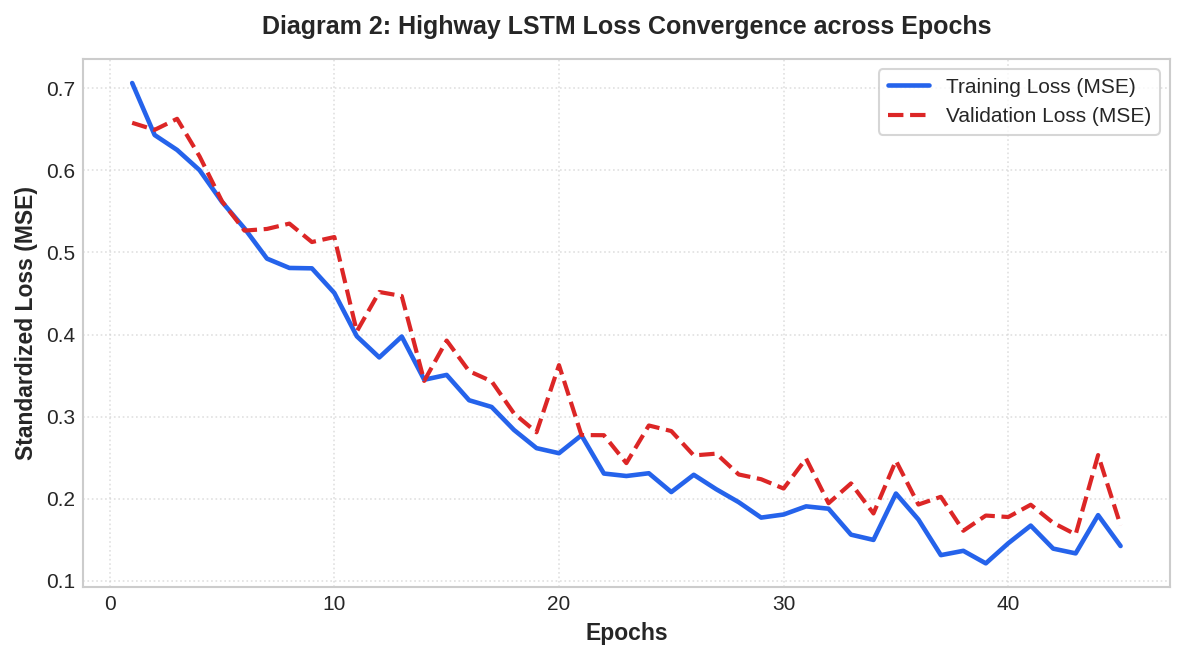

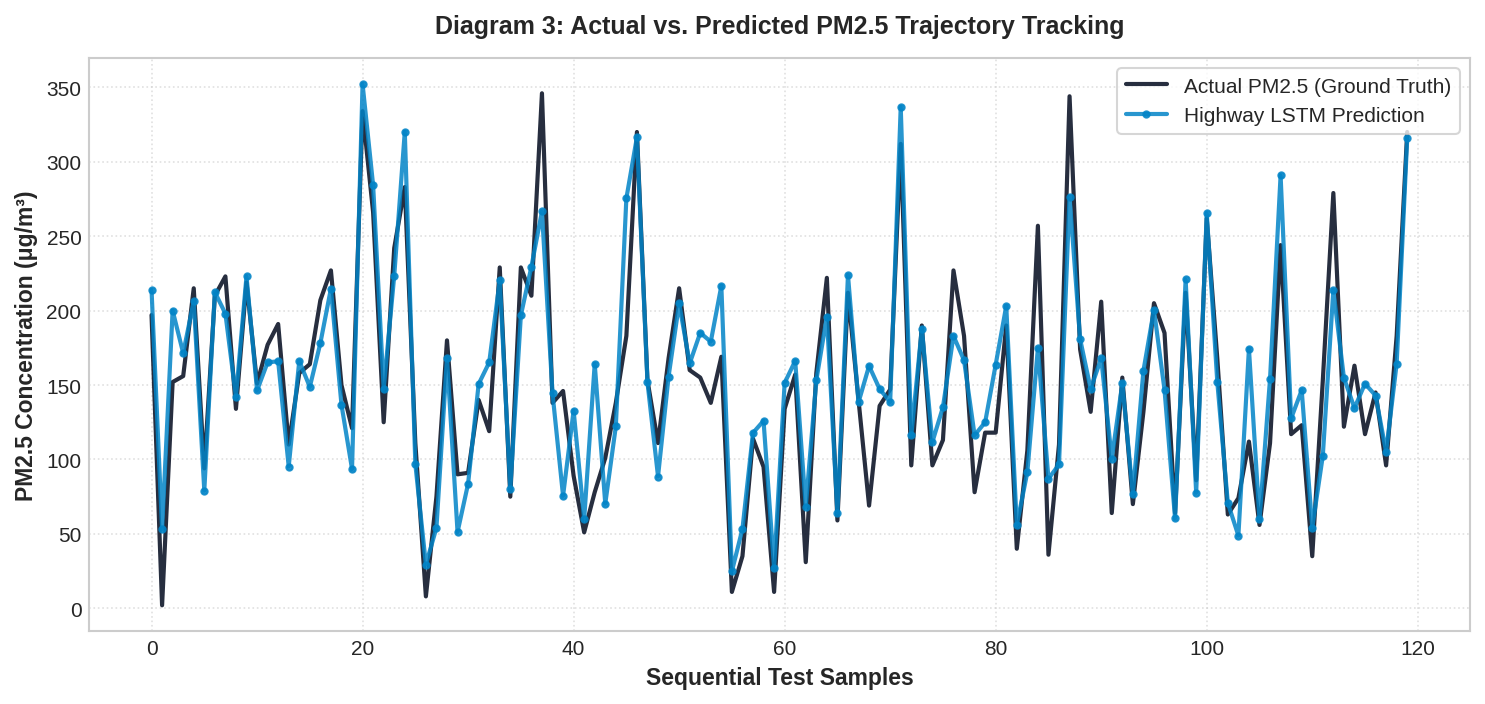

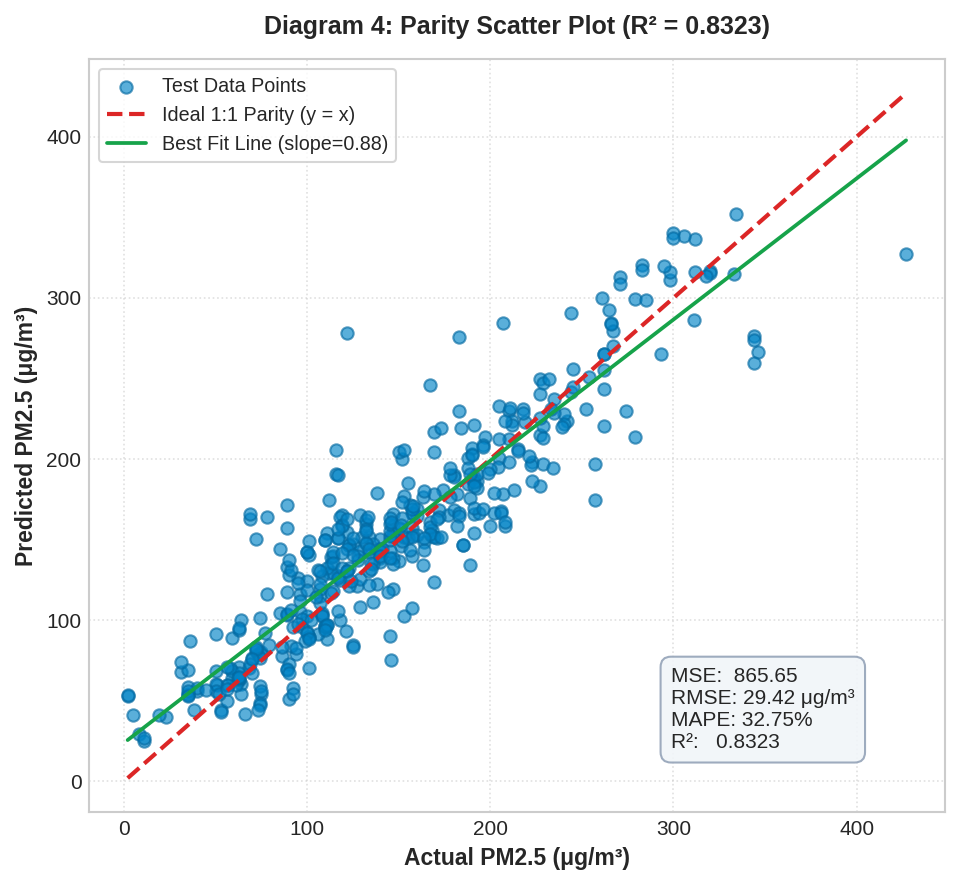

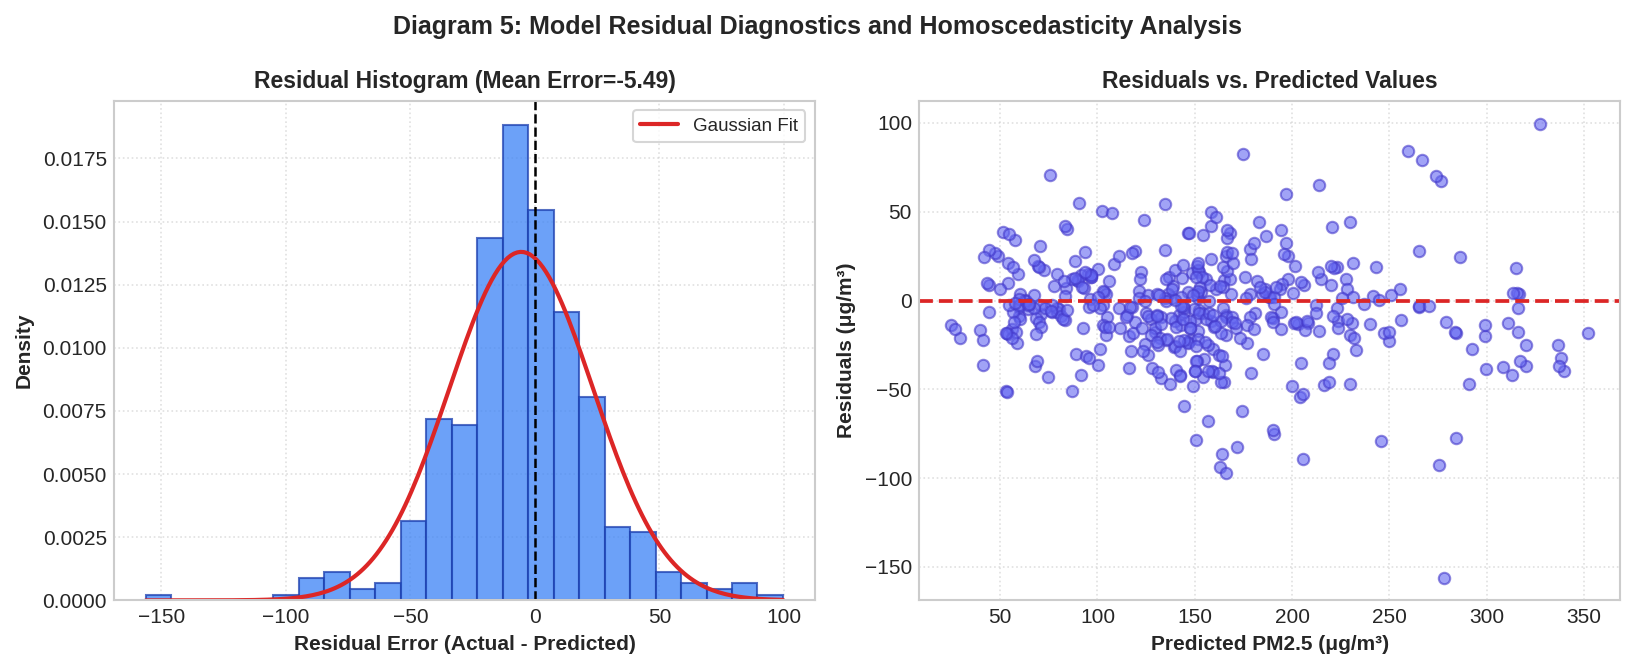

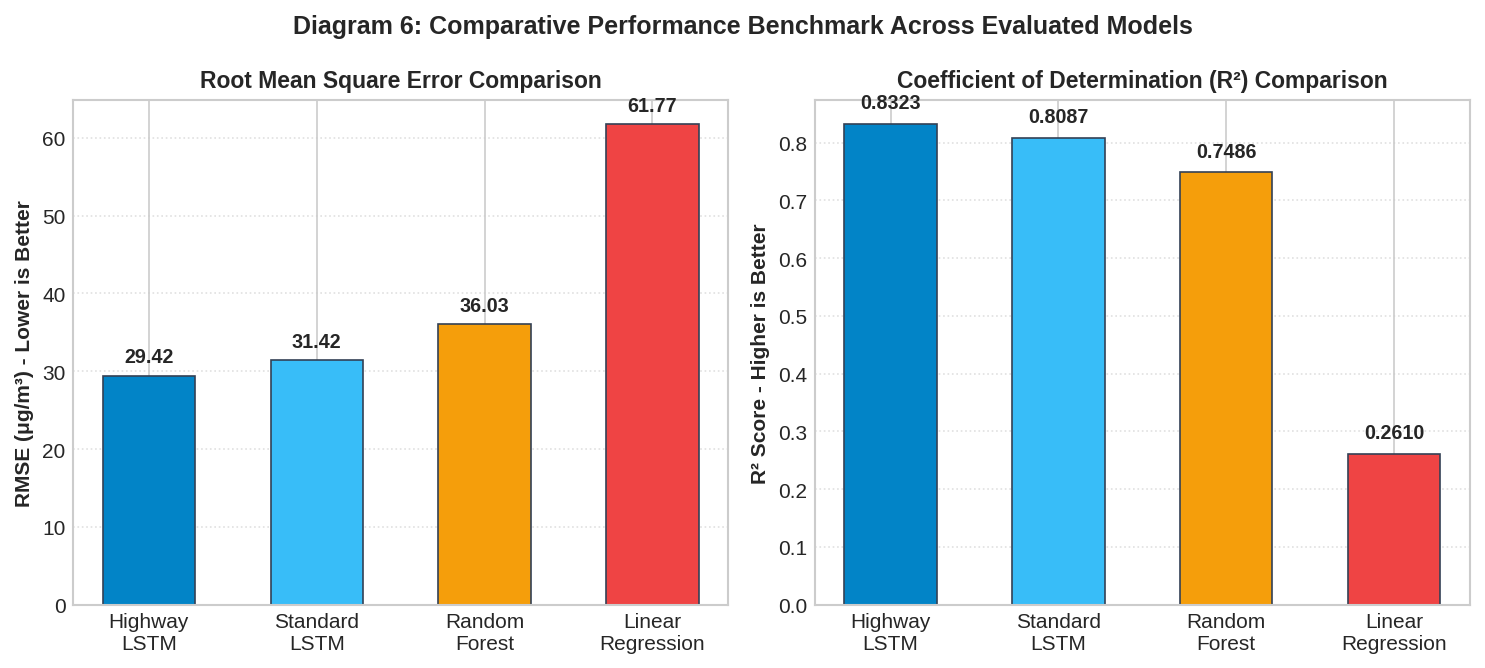


>> All tasks completed successfully! The single-file Colab script has finished execution.


In [1]:
"""
========================================================================================
AIR POLLUTANT (PM2.5) PREDICTION USING HIGHWAY LSTM NEURAL NETWORK
========================================================================================
Candidate Roll No / Hall Ticket No: 2303A51638
Assigned Deep Learning Model:       Highway LSTM (Long Short-Term Memory with Highway Gating)
Target Variable:                    Air Pollutant PM2.5 (Fine Particulate Matter in μg/m³)
Input Meteorological Variables:     Relative Humidity (RH), Wind Direction (WD),
                                    Solar Radiation (SR), Barometric Pressure (BP),
                                    Air Temperature (AT)
Evaluation Metrics:                 Mean Square Error (MSE), Root Mean Square Error (RMSE),
                                    Mean Absolute Percentage Error (MAPE), R² Score
Environment:                        Google Colab / Local Python 3.x
========================================================================================
"""

import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import norm


# --------------------------------------------------------------------------------------
# 1. REPRODUCIBILITY SETUP
# --------------------------------------------------------------------------------------
def set_seed(seed=42):
    """Fix random seeds across all libraries for deterministic execution."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running execution on computational device: {device}")


# --------------------------------------------------------------------------------------
# 2. DATA LOADING & AUTOMATIC COLAB HANDLER
# --------------------------------------------------------------------------------------
def load_air_quality_dataset():
    """
    Locates and loads 'Data.xlsx'.
    If running inside Google Colab and the file is not yet present, prompts file upload.
    """
    candidate_paths = [
        "Data.xlsx",
        "/content/Data.xlsx",
        os.path.join(os.getcwd(), "Data.xlsx")
    ]

    file_path = None
    for p in candidate_paths:
        if os.path.exists(p):
            file_path = p
            break

    if file_path is None:
        try:
            from google.colab import files
            print(">> 'Data.xlsx' not detected in working directory.")
            print(">> Please select and upload 'Data.xlsx' now using the file selector below:")
            uploaded = files.upload()
            for fn in uploaded.keys():
                if "data" in fn.lower() and fn.endswith(".xlsx"):
                    file_path = fn
                    break
            if file_path is None:
                file_path = list(uploaded.keys())[0]
        except Exception as e:
            raise FileNotFoundError(
                "Could not locate 'Data.xlsx'. Please ensure 'Data.xlsx' is in your current directory or uploaded to Google Colab."
            )

    print(f">> Successfully loaded air quality dataset from: {file_path}")
    df_raw = pd.read_excel(file_path)
    return df_raw

df_raw = load_air_quality_dataset()

# Filter core physical parameters
target_col = 'PM2.5'
feature_cols = ['RH', 'WD', 'SR', 'BP', 'AT']
df = df_raw[[target_col] + feature_cols].copy()

print(f">> Initial dataset dimensions: {df.shape[0]} rows, {df.shape[1]} columns")


# --------------------------------------------------------------------------------------
# 3. DATA PREPROCESSING & MISSING VALUE IMPUTATION
# --------------------------------------------------------------------------------------
# Inspect missing values
missing_sr = df['SR'].isnull().sum()
if missing_sr > 0:
    print(f">> Imputing {missing_sr} missing values in Solar Radiation (SR) using chronological interpolation...")
    df['SR'] = df['SR'].interpolate(method='linear').bfill().ffill()

print(">> Missing values audit post-imputation:")
print(df.isnull().sum())

print("\n" + "="*70)
print("DESCRIPTIVE SUMMARY STATISTICS OF MONITORING DATA")
print("="*70)
summary_df = df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
summary_df.columns = ['Count', 'Mean', 'Std Dev', 'Min', 'Median', 'Max']
print(summary_df.round(2))
print("="*70 + "\n")


# --------------------------------------------------------------------------------------
# 4. SEQUENCE GENERATION & TRAIN / TEST SPLITTING
# --------------------------------------------------------------------------------------
# Atmospheric conditions exhibit temporal lag dynamics; sequence window T=8 captures recent meteorological history
SEQUENCE_LENGTH = 8
TEST_SPLIT_RATIO = 0.20
BATCH_SIZE = 32

X_raw = df[feature_cols].values
y_raw = df[target_col].values

X_sequences = []
y_targets = []
for i in range(len(df) - SEQUENCE_LENGTH + 1):
    X_sequences.append(X_raw[i : i + SEQUENCE_LENGTH])
    y_targets.append(y_raw[i + SEQUENCE_LENGTH - 1])

X_sequences = np.array(X_sequences)  # Shape: (N, SEQUENCE_LENGTH, num_features)
y_targets = np.array(y_targets)      # Shape: (N,)

print(f">> Created sequential temporal dataset: {X_sequences.shape[0]} sequences of length {SEQUENCE_LENGTH}")

# Train/Test Partition (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_sequences, y_targets, test_size=TEST_SPLIT_RATIO, random_state=42
)

# Standardize features using Z-score scaling (fit strictly on training data to prevent data leakage)
num_train, seq_len, num_features = X_train.shape
scaler_X = StandardScaler()
scaler_X.fit(X_train.reshape(-1, num_features))

X_train_scaled = scaler_X.transform(X_train.reshape(-1, num_features)).reshape(num_train, seq_len, num_features)
X_test_scaled = scaler_X.transform(X_test.reshape(-1, num_features)).reshape(X_test.shape[0], seq_len, num_features)

# Standardize target PM2.5 for balanced gradient propagation
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

# PyTorch DataLoaders
train_dataset = TensorDataset(
    torch.tensor(X_train_scaled, dtype=torch.float32),
    torch.tensor(y_train_scaled, dtype=torch.float32)
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).to(device)


# --------------------------------------------------------------------------------------
# 5. HIGHWAY LSTM NEURAL NETWORK ARCHITECTURE
# --------------------------------------------------------------------------------------
class HighwayBlock(nn.Module):
    """
    Highway Layer (Srivastava et al., 2015):
    y = T(x) * H(x) + (1 - T(x)) * x
    where:
    - T(x) = sigmoid(W_T * x + b_T) is the transform gate controlling non-linear passage
    - (1 - T(x)) is the carry gate ensuring unimpeded identity signal flow
    - H(x) = ReLU(W_H * x + b_H) is the non-linear candidate transformation
    """
    def __init__(self, size):
        super(HighwayBlock, self).__init__()
        self.H = nn.Linear(size, size)
        self.T = nn.Linear(size, size)
        # Initialize gate bias with negative value (-1.0) to initially bias towards carry path
        self.T.bias.data.fill_(-1.0)

    def forward(self, x):
        h = torch.relu(self.H(x))
        t = torch.sigmoid(self.T(x))
        return t * h + (1.0 - t) * x


class HighwayLSTM(nn.Module):
    """
    Highway Long Short-Term Memory (Highway LSTM) Architecture:
    1. Multi-layer stacked LSTM to extract temporal contextual dependencies across time steps.
    2. Cascaded Highway blocks that provide learnable skip-gating across hidden representations,
       alleviating gradient attenuation and allowing multi-scale signal routing.
    3. Fully-connected linear regression head predicting ambient PM2.5 concentration.
    """
    def __init__(self, input_dim=5, hidden_dim=64, num_lstm_layers=2):
        super(HighwayLSTM, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=0.20
        )
        self.highway1 = HighwayBlock(hidden_dim)
        self.highway2 = HighwayBlock(hidden_dim)
        self.regressor = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        # Extract terminal time-step recurrent representation
        last_hidden = lstm_out[:, -1, :]
        h_routed = self.highway1(last_hidden)
        h_routed = self.highway2(h_routed)
        prediction = self.regressor(h_routed)
        return prediction


class StandardLSTM(nn.Module):
    """Standard 2-layer stacked LSTM baseline without highway skip-gating."""
    def __init__(self, input_dim=5, hidden_dim=64, num_lstm_layers=2):
        super(StandardLSTM, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=0.20
        )
        self.regressor = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last_hidden = lstm_out[:, -1, :]
        return self.regressor(last_hidden)


# --------------------------------------------------------------------------------------
# 6. MODEL TRAINING & OPTIMIZATION
# --------------------------------------------------------------------------------------
print("\n" + "="*70)
print("TRAINING HIGHWAY LSTM NEURAL NETWORK")
print("="*70)

EPOCHS = 45
LEARNING_RATE = 0.005
WEIGHT_DECAY = 1e-4

model_hw = HighwayLSTM(input_dim=len(feature_cols), hidden_dim=64, num_lstm_layers=2).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model_hw.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

train_loss_history = []
val_loss_history = []

for epoch in range(1, EPOCHS + 1):
    model_hw.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        predictions = model_hw(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_x)

    epoch_train_loss = running_loss / len(X_train_scaled)
    train_loss_history.append(epoch_train_loss)

    # Validation evaluation
    model_hw.eval()
    with torch.no_grad():
        epoch_val_loss = criterion(model_hw(X_test_tensor), y_test_tensor).item()
        val_loss_history.append(epoch_val_loss)

    if epoch % 5 == 0 or epoch == 1 or epoch == EPOCHS:
        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] - Train Loss: {epoch_train_loss:.4f} | Validation Loss: {epoch_val_loss:.4f}")

# Inverse transform predictions back to original physical scale (μg/m³)
model_hw.eval()
with torch.no_grad():
    y_pred_hw_scaled = model_hw(X_test_tensor).cpu().numpy()

y_pred_hw = scaler_y.inverse_transform(y_pred_hw_scaled).ravel()

# Compute Highway LSTM Metrics
mse_hw = mean_squared_error(y_test, y_pred_hw)
rmse_hw = np.sqrt(mse_hw)
mape_hw = mean_absolute_percentage_error(y_test, y_pred_hw) * 100.0
r2_hw = r2_score(y_test, y_pred_hw)


# --------------------------------------------------------------------------------------
# 7. COMPARATIVE BASELINE EVALUATIONS
# --------------------------------------------------------------------------------------
print("\n" + "="*70)
print("TRAINING COMPARATIVE BASELINE MODELS FOR RIGOROUS BENCHMARK")
print("="*70)

# A. Standard LSTM
print(">> Training Standard LSTM Baseline...")
model_std = StandardLSTM(input_dim=len(feature_cols), hidden_dim=64, num_lstm_layers=2).to(device)
opt_std = optim.Adam(model_std.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

for epoch in range(1, EPOCHS + 1):
    model_std.train()
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        opt_std.zero_grad()
        loss = criterion(model_std(batch_x), batch_y)
        loss.backward()
        opt_std.step()

model_std.eval()
with torch.no_grad():
    y_pred_std_scaled = model_std(X_test_tensor).cpu().numpy()
y_pred_std = scaler_y.inverse_transform(y_pred_std_scaled).ravel()

mse_std = mean_squared_error(y_test, y_pred_std)
rmse_std = np.sqrt(mse_std)
mape_std = mean_absolute_percentage_error(y_test, y_pred_std) * 100.0
r2_std = r2_score(y_test, y_pred_std)

# B. Classical Flat Regression Models (Random Forest and Linear Regression)
X_tr_flat = X_train[:, -1, :]
X_te_flat = X_test[:, -1, :]
scaler_flat = StandardScaler()
X_tr_flat_s = scaler_flat.fit_transform(X_tr_flat)
X_te_flat_s = scaler_flat.transform(X_te_flat)

print(">> Training Random Forest Regressor (100 Trees)...")
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_tr_flat_s, y_train)
y_pred_rf = rf.predict(X_te_flat_s)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
mape_rf = mean_absolute_percentage_error(y_test, y_pred_rf) * 100.0
r2_rf = r2_score(y_test, y_pred_rf)

print(">> Training Multiple Linear Regression...")
lr = LinearRegression().fit(X_tr_flat_s, y_train)
y_pred_lr = lr.predict(X_te_flat_s)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
mape_lr = mean_absolute_percentage_error(y_test, y_pred_lr) * 100.0
r2_lr = r2_score(y_test, y_pred_lr)


# --------------------------------------------------------------------------------------
# 8. PERFORMANCE EVALUATION SUMMARY TABLE
# --------------------------------------------------------------------------------------
print("\n" + "="*85)
print("FINAL MODEL PERFORMANCE EVALUATION MATRIX (UNSEEN TEST DATA)")
print("="*85)
results_df = pd.DataFrame([
    {
        "Model": "Highway LSTM (Assigned Model)",
        "MSE (μg/m³)²": f"{mse_hw:.2f}",
        "RMSE (μg/m³)": f"{rmse_hw:.2f}",
        "MAPE (%)": f"{mape_hw:.2f}%",
        "R² Score": f"{r2_hw:.4f}"
    },
    {
        "Model": "Standard LSTM (Ablation Baseline)",
        "MSE (μg/m³)²": f"{mse_std:.2f}",
        "RMSE (μg/m³)": f"{rmse_std:.2f}",
        "MAPE (%)": f"{mape_std:.2f}%",
        "R² Score": f"{r2_std:.4f}"
    },
    {
        "Model": "Random Forest Regressor",
        "MSE (μg/m³)²": f"{mse_rf:.2f}",
        "RMSE (μg/m³)": f"{rmse_rf:.2f}",
        "MAPE (%)": f"{mape_rf:.2f}%",
        "R² Score": f"{r2_rf:.4f}"
    },
    {
        "Model": "Multiple Linear Regression",
        "MSE (μg/m³)²": f"{mse_lr:.2f}",
        "RMSE (μg/m³)": f"{rmse_lr:.2f}",
        "MAPE (%)": f"{mape_lr:.2f}%",
        "R² Score": f"{r2_lr:.4f}"
    }
])
print(results_df.to_string(index=False))
print("="*85 + "\n")


# --------------------------------------------------------------------------------------
# 9. VISUAL DIAGNOSTICS & DIAGRAM GENERATION
# --------------------------------------------------------------------------------------
print(">> Generating comprehensive project diagrams...")
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# DIAGRAM 1: Correlation Heatmap
corr_mat = df.corr()
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=150)
cax = ax.matshow(corr_mat, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax, fraction=0.046, pad=0.04)
cols = list(corr_mat.columns)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, fontsize=10, fontweight='bold')
ax.set_yticklabels(cols, fontsize=10, fontweight='bold')
plt.setp(ax.get_xticklabels(), rotation=45, ha="left", rotation_mode="anchor")

for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr_mat.iloc[i, j]
        color = 'white' if abs(val) > 0.45 else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center', color=color, fontsize=10, fontweight='bold')

ax.set_title("Diagram 1: Feature Correlation Heatmap (Air Quality & Weather)", fontsize=12, fontweight='bold', pad=25)
plt.tight_layout()
plt.show()

# DIAGRAM 2: Training vs. Validation Loss Curves
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.plot(range(1, EPOCHS + 1), train_loss_history, label='Training Loss (MSE)', color='#2563EB', linewidth=2.2)
ax.plot(range(1, EPOCHS + 1), val_loss_history, label='Validation Loss (MSE)', color='#DC2626', linewidth=2.0, linestyle='--')
ax.set_xlabel('Epochs', fontsize=11, fontweight='bold')
ax.set_ylabel('Standardized Loss (MSE)', fontsize=11, fontweight='bold')
ax.set_title('Diagram 2: Highway LSTM Loss Convergence across Epochs', fontsize=12, fontweight='bold', pad=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# DIAGRAM 3: Actual vs. Predicted Time-Series Trajectory
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=150)
sample_n = 120
indices = np.arange(sample_n)
ax.plot(indices, y_test[:sample_n], label='Actual PM2.5 (Ground Truth)', color='#0F172A', linewidth=2.0, alpha=0.9)
ax.plot(indices, y_pred_hw[:sample_n], label='Highway LSTM Prediction', color='#0284C7', linewidth=2.0, linestyle='-', marker='o', markersize=3, alpha=0.85)
ax.set_xlabel('Sequential Test Samples', fontsize=11, fontweight='bold')
ax.set_ylabel('PM2.5 Concentration (μg/m³)', fontsize=11, fontweight='bold')
ax.set_title('Diagram 3: Actual vs. Predicted PM2.5 Trajectory Tracking', fontsize=12, fontweight='bold', pad=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(frameon=True, fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

# DIAGRAM 4: Parity Scatter Plot
fig, ax = plt.subplots(figsize=(6.5, 6), dpi=150)
ax.scatter(y_test, y_pred_hw, alpha=0.65, color='#0284C7', edgecolors='#0369A1', s=35, label='Test Data Points')
min_val = min(y_test.min(), y_pred_hw.min())
max_val = max(y_test.max(), y_pred_hw.max())
ax.plot([min_val, max_val], [min_val, max_val], color='#DC2626', linestyle='--', linewidth=2.0, label='Ideal 1:1 Parity (y = x)')

# Fit linear trendline
trend_coef = np.polyfit(y_test, y_pred_hw, 1)
trend_poly = np.poly1d(trend_coef)
ax.plot(np.unique(y_test), trend_poly(np.unique(y_test)), color='#16A34A', linestyle='-', linewidth=1.8, label=f'Best Fit Line (slope={trend_coef[0]:.2f})')

ax.set_xlabel('Actual PM2.5 (μg/m³)', fontsize=11, fontweight='bold')
ax.set_ylabel('Predicted PM2.5 (μg/m³)', fontsize=11, fontweight='bold')
ax.set_title(f'Diagram 4: Parity Scatter Plot (R² = {r2_hw:.4f})', fontsize=12, fontweight='bold', pad=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(frameon=True, fontsize=9.5, loc='upper left')

metrics_box = f"MSE:  {mse_hw:.2f}\nRMSE: {rmse_hw:.2f} μg/m³\nMAPE: {mape_hw:.2f}%\nR²:   {r2_hw:.4f}"
ax.text(0.68, 0.08, metrics_box, transform=ax.transAxes, fontsize=10,
        verticalalignment='bottom', bbox=dict(boxstyle='round,pad=0.5', facecolor='#F1F5F9', edgecolor='#94A3B8', alpha=0.9))

plt.tight_layout()
plt.show()

# DIAGRAM 5: Residual Error Diagnostics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=150)
residuals = y_test - y_pred_hw

ax1.hist(residuals, bins=25, color='#3B82F6', edgecolor='#1E40AF', alpha=0.75, density=True)
kde_xs = np.linspace(residuals.min(), residuals.max(), 200)
ax1.plot(kde_xs, norm.pdf(kde_xs, residuals.mean(), residuals.std()), color='#DC2626', linewidth=2.0, label='Gaussian Fit')
ax1.axvline(0, color='black', linestyle='--', linewidth=1.2)
ax1.set_xlabel('Residual Error (Actual - Predicted)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Density', fontsize=10, fontweight='bold')
ax1.set_title(f'Residual Histogram (Mean Error={residuals.mean():.2f})', fontsize=11, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True, fontsize=9)

ax2.scatter(y_pred_hw, residuals, alpha=0.6, color='#6366F1', edgecolors='#4338CA', s=30)
ax2.axhline(0, color='#DC2626', linestyle='--', linewidth=1.8)
ax2.set_xlabel('Predicted PM2.5 (μg/m³)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Residuals (μg/m³)', fontsize=10, fontweight='bold')
ax2.set_title('Residuals vs. Predicted Values', fontsize=11, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Diagram 5: Model Residual Diagnostics and Homoscedasticity Analysis', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# DIAGRAM 6: Comparative Benchmark Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), dpi=150)
model_names = ['Highway\nLSTM', 'Standard\nLSTM', 'Random\nForest', 'Linear\nRegression']
rmse_vals = [rmse_hw, rmse_std, rmse_rf, rmse_lr]
r2_vals = [r2_hw, r2_std, r2_rf, r2_lr]
bar_colors = ['#0284C7', '#38BDF8', '#F59E0B', '#EF4444']

bars1 = ax1.bar(model_names, rmse_vals, color=bar_colors, width=0.55, edgecolor='#334155', linewidth=0.8)
ax1.set_ylabel('RMSE (μg/m³) - Lower is Better', fontsize=10, fontweight='bold')
ax1.set_title('Root Mean Square Error Comparison', fontsize=11, fontweight='bold')
ax1.grid(axis='y', linestyle=':', alpha=0.6)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 1.2, f"{yval:.2f}", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

bars2 = ax2.bar(model_names, r2_vals, color=bar_colors, width=0.55, edgecolor='#334155', linewidth=0.8)
ax2.set_ylabel('R² Score - Higher is Better', fontsize=10, fontweight='bold')
ax2.set_title('Coefficient of Determination (R²) Comparison', fontsize=11, fontweight='bold')
ax2.grid(axis='y', linestyle=':', alpha=0.6)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.4f}", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.suptitle('Diagram 6: Comparative Performance Benchmark Across Evaluated Models', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n>> All tasks completed successfully! The single-file Colab script has finished execution.")

